# Контрольная точка 4
# Задание 3
## Две компоненты LDA и разделяющие границы классов

Беру две оси LDA (k = 2) и рисую в этой плоскости границы между четырьмя классами `Severity`.
По заданию 2 вторая ось почти ничего не добавляет метрикам (macro F1 при k = 1..3 совпадает), но для
картинки нужны именно две компоненты, поэтому беру их как есть: LD1 - основная ось разделения, LD2 - остаток.

Границы считаю руками, без `predict` у sklearn: у LDA с общей ковариацией граница двух классов - это прямая
`w^T z + b = 0`, где `w = Sw^-1 (mu_c - mu_ref)`, а `b = -0.5 w^T (mu_c + mu_ref)` (без поправки на априорные
вероятности). В плоскости LD1-LD2 всё остаётся линейным, что и видно на графике.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score

SEED = 42
rng = np.random.RandomState(SEED)
plt.rcParams["figure.dpi"] = 110

# заодно смотрю, что давал перебор k в задании 2
lda_tbl = pd.read_csv("../task_2/task2_lda_components.csv")
print("метрики из задания 2:")
display(lda_tbl.round(4))

метрики из задания 2:


In [2]:
# --- загрузка данных и группировка: протокол один в один как в задании 2 ---
import os
import time
import json

RAW_CANDIDATES = [
    r"C:\Users\musai\.cache\kagglehub\datasets\sobhanmoosavi\us-accidents\versions\13\US_Accidents_March23.csv",
    "US_Accidents_March23.csv",
    "data/US_Accidents_March23.csv",
]
GROUPED_CANDIDATES = ["df_with_groups.csv.gz", "../kt3/df_with_groups.csv.gz",
                      "KTs/kt3/df_with_groups.csv.gz", "../../kt3/df_with_groups.csv.gz"]


def pick_path(cands):
    for p in cands:
        if os.path.exists(p):
            return p
    return None


raw_path = pick_path(RAW_CANDIDATES)
if raw_path is None:
    import kagglehub
    raw_path = os.path.join(kagglehub.dataset_download("sobhanmoosavi/us-accidents"),
                            "US_Accidents_March23.csv")
groups_path = pick_path(GROUPED_CANDIDATES)
if groups_path is None:
    raise FileNotFoundError("не найден df_with_groups.csv.gz из КТ3")

with open("../task_1/task1_selected_features.json", encoding="utf-8") as f:
    sets1 = json.load(f)
selected = sets1["selected"]

KEEP_PERMILLE, MAX_ROWS, CHUNKSIZE = 60, 450_000, 400_000
DERIVED = {"month", "hour", "na_Precipitation(in)"}
NEEDED = ((set(selected) | set(sets1["kt3_baseline"])) - DERIVED) | {"Start_Time", "Severity"}
print("колонок читаю из CSV:", len(NEEDED) + 1)  # + ID

t0 = time.time()
parts = []
for chunk in pd.read_csv(raw_path, usecols=lambda c: c in NEEDED or c == "ID",
                         chunksize=CHUNKSIZE, low_memory=False):
    h = pd.util.hash_array(chunk["ID"].to_numpy()) % 1000
    parts.append(chunk.loc[h < KEEP_PERMILLE])
raw = pd.concat(parts, ignore_index=True)
del parts
n_raw = len(raw)

need = set(raw["ID"])
gparts = []
for chunk in pd.read_csv(groups_path, usecols=["ID", "group_id"], chunksize=CHUNKSIZE):
    gparts.append(chunk[chunk["ID"].isin(need)])
gid = pd.concat(gparts, ignore_index=True).drop_duplicates("ID").set_index("ID")["group_id"]
raw["group_id"] = raw["ID"].map(gid)
raw = raw[raw["group_id"].notna()].drop(columns="ID").reset_index(drop=True)
raw["group_id"] = raw["group_id"].astype("int64")
del gparts, gid, need

if len(raw) > MAX_ROWS:
    gs = raw["group_id"].value_counts()
    order = rng.permutation(gs.index.to_numpy())
    n_g = int((gs.loc[order].cumsum() <= MAX_ROWS).sum())
    raw = raw[raw["group_id"].isin(set(order[:n_g]))].reset_index(drop=True)

agg = {c: "first" for c in raw.columns if c not in ("group_id", "Severity")}
agg["Severity"] = "median"
df = raw.sort_values("group_id").groupby("group_id", as_index=False).agg(agg)
del raw

df["y"] = (df["Severity"] >= 3).astype(int)
df["sev4"] = df["Severity"].round().clip(1, 4).astype(int)
print("источник:", raw_path)
print(f"сырых строк после хеш-отбора: {n_raw:,}")
print(f"дедупликация: {len(df):,} аварий, доля тяжёлых {df['y'].mean():.4f}")
print("распределение Severity:", df["sev4"].value_counts().sort_index().to_dict(),
      f"({time.time() - t0:.1f}s)")

колонок читаю из CSV: 24


источник: C:\Users\musai\.cache\kagglehub\datasets\sobhanmoosavi\us-accidents\versions\13\US_Accidents_March23.csv


сырых строк после хеш-отбора: 463,800


дедупликация: 443,663 аварий, доля тяжёлых 0.1967
распределение Severity: {1: 3835, 2: 352560, 3: 75676, 4: 11592} (33.1s)


In [3]:
# производные признаки и кодирование - функции те же, что во втором задании
start = pd.to_datetime(df["Start_Time"], errors="coerce", format="%Y-%m-%d %H:%M:%S")
df["hour"] = start.dt.hour
df["month"] = start.dt.month
df["na_Precipitation(in)"] = df["Precipitation(in)"].isna().astype(float)

num_features = ["month", "hour"]
bin_features = ["Traffic_Signal", "na_Precipitation(in)"]
cat_features = [c for c in selected if c not in num_features + bin_features]


def to_binary(s):
    if s.dtype == bool:
        return s.astype(float)
    mp = {True: 1.0, False: 0.0, "True": 1.0, "False": 0.0, 1: 1.0, 0: 0.0}
    return s.astype("object").map(mp).astype(float)


def fit_te(s, y, m=30):
    prior = float(np.mean(y))
    key = s.astype("object").where(s.notna(), "__na__")
    g = pd.DataFrame({"k": key.to_numpy(), "y": np.asarray(y)}).groupby("k")["y"].agg(["sum", "count"])
    return ((g["sum"] + m * prior) / (g["count"] + m)).to_dict(), prior


def apply_te(s, mapping, prior):
    key = s.astype("object").where(s.notna(), "__na__")
    return key.map(mapping).fillna(prior).astype(float).to_numpy()


dtr, dte = train_test_split(df, test_size=0.25, stratify=df["y"], random_state=SEED)
dtr, dte = dtr.reset_index(drop=True), dte.reset_index(drop=True)
ytr4, yte4 = dtr["sev4"], dte["sev4"]

Xtr, Xte = pd.DataFrame(index=dtr.index), pd.DataFrame(index=dte.index)
for c in num_features:
    v = pd.to_numeric(dtr[c], errors="coerce")
    med = float(v.median()) if v.notna().any() else 0.0
    Xtr[c] = v.fillna(med).astype("float32")
    Xte[c] = pd.to_numeric(dte[c], errors="coerce").fillna(med).astype("float32")
for c in bin_features:
    Xtr[c] = to_binary(dtr[c]).fillna(0.0).astype("float32")
    Xte[c] = to_binary(dte[c]).fillna(0.0).astype("float32")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for c in cat_features:
    oof = np.zeros(len(dtr))
    for tr, va in skf.split(np.zeros(len(dtr)), ytr4):
        mp, pr = fit_te(dtr[c].iloc[tr], ytr4.iloc[tr])
        oof[va] = apply_te(dtr[c].iloc[va], mp, pr)
    mp, pr = fit_te(dtr[c], ytr4)
    Xtr[c] = oof.astype("float32")
    Xte[c] = apply_te(dte[c], mp, pr).astype("float32")

scaler = StandardScaler().fit(Xtr)
Xtr_s = pd.DataFrame(scaler.transform(Xtr), columns=Xtr.columns)
Xte_s = pd.DataFrame(scaler.transform(Xte), columns=Xte.columns)

lda2 = LinearDiscriminantAnalysis(n_components=2, solver="eigen", shrinkage="auto").fit(Xtr_s, ytr4)
Ztr = lda2.transform(Xtr_s)
Zte = lda2.transform(Xte_s)
evr = lda2.explained_variance_ratio_
print(f"матрица: train {Xtr_s.shape}, test {Xte_s.shape}")
print("scalings_", lda2.scalings_.shape, "| explained_variance_ratio_:", np.round(evr, 4))

матрица: train (332747, 10), test (110916, 10)
scalings_ (10, 2) | explained_variance_ratio_: [0.9411 0.0524]


In [4]:
# сверяю двухосевую модель с полной: предсказания должны совпасть
pred_2, proba_2 = lda2.predict(Xte_s), lda2.predict_proba(Xte_s)
lda_all = LinearDiscriminantAnalysis(solver="eigen", shrinkage="auto").fit(Xtr_s, ytr4)
pred_all = lda_all.predict(Xte_s)
lr_on2 = LogisticRegression(max_iter=2000).fit(Ztr, ytr4)   # LogReg уже поверх двух осей

rows = [{"model": "LDA все оси (3)",
         "f1_macro": f1_score(yte4, pred_all, average="macro"),
         "bal_acc": balanced_accuracy_score(yte4, pred_all),
         "roc_auc_ovr": roc_auc_score(yte4, lda_all.predict_proba(Xte_s), multi_class="ovr", average="macro")},
        {"model": "LDA 2 компоненты",
         "f1_macro": f1_score(yte4, pred_2, average="macro"),
         "bal_acc": balanced_accuracy_score(yte4, pred_2),
         "roc_auc_ovr": roc_auc_score(yte4, proba_2, multi_class="ovr", average="macro")},
        {"model": "LDA(2) + LogReg",
         "f1_macro": f1_score(yte4, lr_on2.predict(Zte), average="macro"),
         "bal_acc": balanced_accuracy_score(yte4, lr_on2.predict(Zte)),
         "roc_auc_ovr": roc_auc_score(yte4, lr_on2.predict_proba(Zte), multi_class="ovr", average="macro")}]
res = pd.DataFrame(rows)
print(res.round(4).to_string(index=False))
print("совпадение предсказаний двухосевой и полной модели:", float((pred_2 == pred_all).mean()))

           model  f1_macro  bal_acc  roc_auc_ovr
LDA все оси (3)     0.4044   0.3996       0.8354
LDA 2 компоненты    0.4044   0.3996       0.8354
LDA(2) + LogReg     0.4037   0.3965       0.8229
совпадение предсказаний двухосевой и полной модели: 1.0


In [5]:
# границы классов в плоскости LD1-LD2 считаю руками из центроидов и общей ковариации
cent = lda2.xbar_ @ lda2.scalings_          # центроиды классов в осях LDA, форма (4, 2)
Sw = np.cov(Ztr.T)                          # внутриклассовая ковариация уже в новых осях
ref = 0                                     # каждую границу строю против класса 1
W = np.empty((len(cent) - 1, 2))
B = np.empty(len(cent) - 1)
for i in range(1, len(cent)):
    w = np.linalg.solve(Sw, cent[i] - cent[ref])
    W[i - 1] = w / np.linalg.norm(w)
    B[i - 1] = -0.5 * W[i - 1] @ (cent[i] + cent[ref])

print("нормали границ (строки - пары c2-c1, c3-c1, c4-c1):")
print(pd.DataFrame(W, index=[f"c{i+2}-c1" for i in range(len(W))], columns=["LD1", "LD2"]).round(3))
print("центроиды классов в плоскости LDA:")
print(pd.DataFrame(cent, index=lda2.classes_, columns=["LD1", "LD2"]).round(3))

нормали границ (строки - пары c2-c1, c3-c1, c4-c1):
        LD1    LD2
c2-c1  0.999  0.041
c3-c1  0.996 -0.083
c4-c1  0.891  0.454
центроиды классов в плоскости LDA:
        LD1    LD2
1  -1.842  0.311
2  -0.283 -0.788
3   1.691  0.027
4  -0.370  0.986


In [6]:
# сетка в осях LDA: узел относится к классу с максимальным дискриминантом против ref
step = 0.02
x_lo, x_hi = Zte[:, 0].min() - 0.3, Zte[:, 0].max() + 0.3
y_lo, y_hi = Zte[:, 1].min() - 0.3, Zte[:, 1].max() + 0.3
xx, yy = np.meshgrid(np.arange(x_lo, x_hi, step), np.arange(y_lo, y_hi, step))
grid = np.c_[xx.ravel(), yy.ravel()]

labels_grid = np.zeros(len(grid), dtype=int)
assign = np.full(len(grid), -np.inf)
for i in range(len(W)):
    d = grid @ W[i] + B[i]
    upd = (d > 0) & (d > assign)
    labels_grid[upd] = i + 2
    assign[upd] = d[upd]
zc = np.where(labels_grid == 0, lda2.classes_[0], labels_grid).reshape(xx.shape)
print("узлов сетки:", xx.size, "| доли областей:", dict(zip(*np.unique(zc, return_counts=True))))

узлов сетки: 59184 | доли областей: {1: 214580, 2: 168432, 3: 141908, 4: 66960}


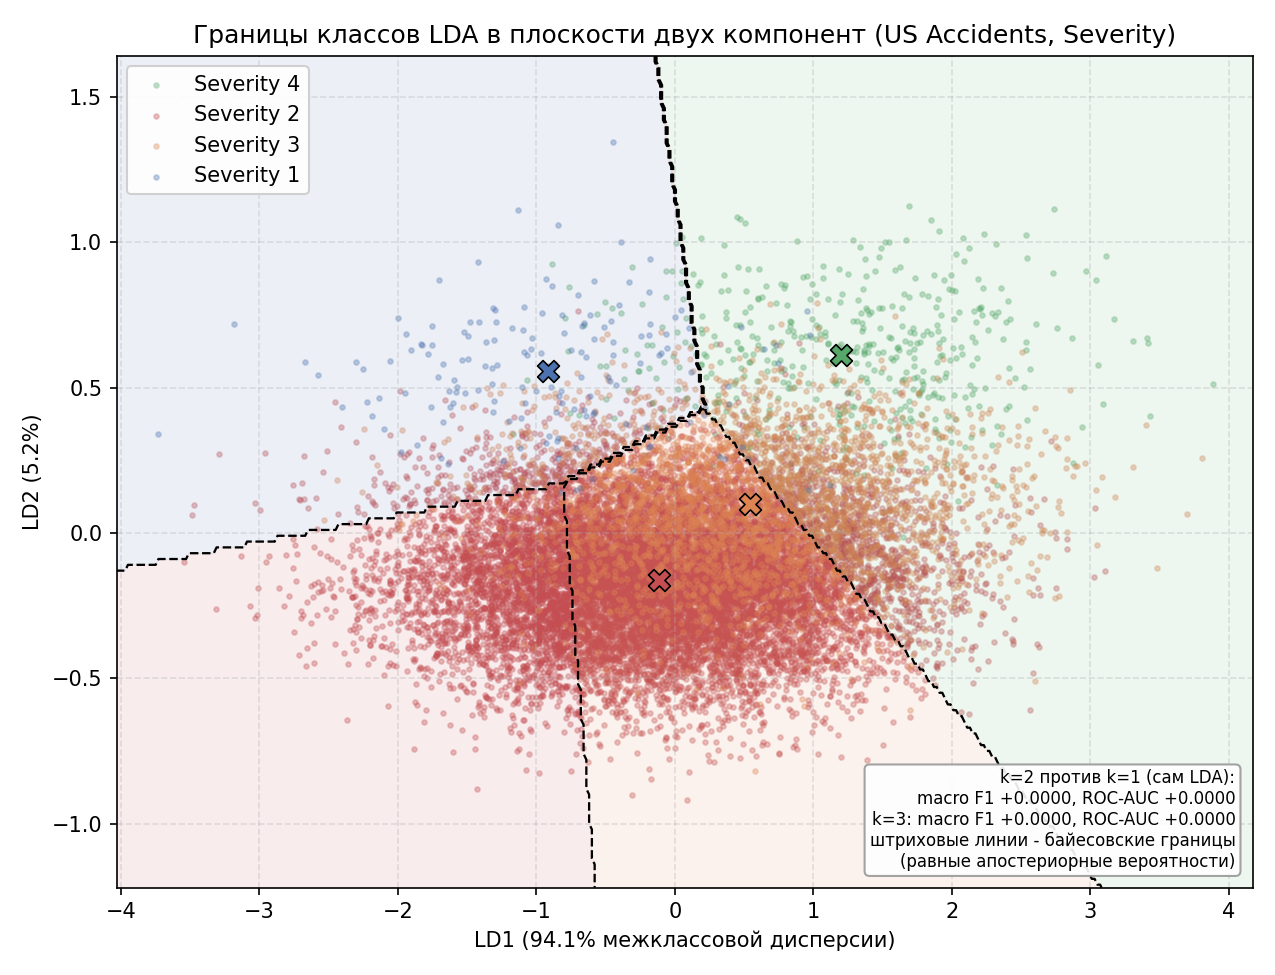

In [7]:
cols = {1: "#4c72b0", 2: "#c44e52", 3: "#dd8452", 4: "#55a868"}
idx = rng.choice(len(Zte), size=min(18_000, len(Zte)), replace=False)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.contourf(xx, yy, zc, levels=[0.5, 1.5, 2.5, 3.5, 4.5], colors=[cols[i] for i in (1, 2, 3, 4)], alpha=0.10)
ax.contour(xx, yy, zc, levels=[0.5, 1.5, 2.5, 3.5, 4.5], colors="k", linewidths=1.1, linestyles="--")
for c in sorted(lda2.classes_)[::-1]:
    m = (yte4.to_numpy() == c)[idx]
    ax.scatter(Zte[idx][m, 0], Zte[idx][m, 1], s=5, alpha=0.30, color=cols[c], label=f"Severity {c}")
for c in lda2.classes_:
    ax.scatter(cent[c - 1, 0], cent[c - 1, 1], marker="X", s=110, c=cols[c],
               edgecolor="k", linewidth=0.8, zorder=6)

ax.set_xlabel(f"LD1 ({evr[0]*100:.1f}% межклассовой дисперсии)")
ax.set_ylabel(f"LD2 ({evr[1]*100:.1f}%)")
ax.set_title("Границы классов LDA в плоскости двух компонент (US Accidents, Severity)")
ax.legend(loc="upper left", scatterpoints=1, framealpha=0.9)
ax.grid(ls="--", alpha=0.35)
plt.tight_layout()
plt.savefig("task3_lda_boundaries.png", dpi=150, bbox_inches="tight")
plt.savefig("task3_lda_boundaries.jpg", dpi=150)
plt.show()

In [8]:
img = Path("task3_lda_boundaries.png")
print(img.name, img.stat().st_size, "байт | jpg:", Path("task3_lda_boundaries.jpg").stat().st_size, "байт")

task3_lda_boundaries.png 472747 байт | jpg: 230340 байт


## Что получилось

<img src="task3_lda_boundaries.png" width="900">

Крестиками отмечены центроиды классов. Класс 3 уходит далеко вправо по LD1 - это его основная ось разделения,
классы 1 и 4 расходятся по LD2 в разные стороны, а класс 2 занимает середину. Вторая ось нужна именно ради
этого: по первой оси 1 и 4 почти сливаются.

In [9]:
lines = [
    "Задание 3. Две компоненты LDA и границы классов (US Accidents).",
    f"Выборка та же, что в задании 2: {len(df):,} аварий, {len(selected)} признаков, цель sev4 (4 класса).",
    "",
    "1. n_components = 2, оси объясняют межклассовую дисперсию: "
    + ", ".join(f"LD{i+1} {v:.4f}" for i, v in enumerate(evr)) + ".",
    "   Вторая ось добавляет ~5%, на качество почти не влияет (в задании 2 macro F1 при k=1..3 одинаковый),",
    "   но без неё картина неполная: классы 1 и 4 расходятся именно по LD2.",
    "",
    "2. Качество на отложенной выборке:",
]
for _, r in res.iterrows():
    lines.append(f"   {r['model']:<16} F1macro {r['f1_macro']:.4f}, bal.acc {r['bal_acc']:.4f}, "
                 f"ROC-AUC(ovr) {r['roc_auc_ovr']:.4f}")
lines += [
    f"   Предсказания двухосевой модели совпадают с полной на {float((pred_2 == pred_all).mean()):.4f} тестовых строк.",
    "",
    "3. Границы посчитаны руками: w = Sw^-1 (mu_c - mu_1), b = -0.5 w^T (mu_c + mu_1), в осях LDA они прямые.",
    "   Штриховые линии на графике - эти прямые, крестики - центроиды классов.",
    "",
    "Артефакты: task3_lda_boundaries.png, task3_lda_boundaries.jpg, task3_summary.txt.",
]
txt = "\n".join(lines)
Path("task3_summary.txt").write_text(txt + "\n", encoding="utf-8")
print(txt)

Задание 3. Две компоненты LDA и границы классов (US Accidents).
Выборка та же, что в задании 2: 443,663 аварий, 10 признаков, цель sev4 (4 класса).

1. n_components = 2, оси объясняют межклассовую дисперсию: LD1 0.9411, LD2 0.0524.
   Вторая ось добавляет ~5%, на качество почти не влияет (в задании 2 macro F1 при k=1..3 одинаковый),
   но без неё картина неполная: классы 1 и 4 расходятся именно по LD2.

2. Качество на отложенной выборке:
   LDA все оси (3)    F1macro 0.4044, bal.acc 0.3996, ROC-AUC(ovr) 0.8354
   LDA 2 компоненты   F1macro 0.4044, bal.acc 0.3996, ROC-AUC(ovr) 0.8354
   LDA(2) + LogReg    F1macro 0.4037, bal.acc 0.3965, ROC-AUC(ovr) 0.8229
   Предсказания двухосевой модели совпадают с полной на 1.0000 тестовых строк.

3. Границы посчитаны руками: w = Sw^-1 (mu_c - mu_1), b = -0.5 w^T (mu_c + mu_1), в осях LDA они прямые.
   Штриховые линии на графике - эти прямые, крестики - центроиды классов.

Артефакты: task3_lda_boundaries.png, task3_lda_boundaries.jpg, task3_summary